In [1]:
print("Program is developed by",u"\u092A\u094D\u0930\u093F\u092F\u093E\u0902\u0936\u0941\u0020\u092E\u093F\u0936\u094D\u0930\u093E")
print("Program is checked by",u"\u0935\u0948\u0936\u093E\u0932\u0940\u0020\u0907\u0902\u0917\u0933\u0947 / \u0936\u094d\u0935\u0947\u0924\u093e \u0935\u093e\u0928\u0916\u0947\u0921\u093c\u0947")

Program is developed by प्रियांशु मिश्रा
Program is checked by वैशाली इंगळे / श्वेता वानखेड़े


In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [30]:
RANDOM_STATE = 42

In [65]:
df = pd.read_csv('Admission_Predict.csv')

In [67]:
df.head(5)

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,0.92
1,2,324,107,4,4.0,4.5,8.87,1,0.76
2,3,316,104,3,3.0,3.5,8.00,1,0.72
3,4,322,110,3,3.5,2.5,8.67,1,0.80
4,5,314,103,2,2.0,3.0,8.21,0,0.65


In [9]:
print("Number of samples:", df.shape[0])
print("Number of features:", df.shape[1])

Number of samples: 400
Number of features: 9


In [11]:
df.columns = df.columns.str.strip()
print("Columns:", df.columns.tolist())

Columns: ['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Chance of Admit']


In [13]:
df.describe()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
count,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000
mean,200.500000,316.807500,107.410000,3.087500,3.400000,3.452500,8.598925,0.547500,0.724350
std,115.614301,11.473646,6.069514,1.143728,1.006869,0.898478,0.596317,0.498362,0.142609
min,1.000000,290.000000,92.000000,1.000000,1.000000,1.000000,6.800000,0.000000,0.340000
25%,100.750000,308.000000,103.000000,2.000000,2.500000,3.000000,8.170000,0.000000,0.640000
50%,200.500000,317.000000,107.000000,3.000000,3.500000,3.500000,8.610000,1.000000,0.730000
75%,300.250000,325.000000,112.000000,4.000000,4.000000,4.000000,9.062500,1.000000,0.830000
max,400.000000,340.000000,120.000000,5.000000,5.000000,5.000000,9.920000,1.000000,0.970000


In [15]:
print("Number of duplicates:", df.duplicated().sum())

Number of duplicates: 0


In [17]:
print("\nMissing values :", df.isna().sum())


Missing values : Serial No.           0
GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
Chance of Admit      0
dtype: int64


In [19]:
df = df.drop(columns=["Serial No."])

In [21]:
target_threshold = df["Chance of Admit"].quantile(0.75)

df["Chance of Admit"] = (df["Chance of Admit"] >= target_threshold).astype(int)

class_names = ["Low", "High"]

print(f"25th-percentile target threshold = {target_threshold:.4f}")

25th-percentile target threshold = 0.8300


In [23]:
df.head(5)

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,337,118,4,4.5,4.5,9.65,1,1
1,324,107,4,4.0,4.5,8.87,1,0
2,316,104,3,3.0,3.5,8.00,1,0
3,322,110,3,3.5,2.5,8.67,1,0
4,314,103,2,2.0,3.0,8.21,0,0


In [25]:
df["Chance of Admit"].value_counts()

Chance of Admit
0    299
1    101
Name: count, dtype: int64

In [27]:
X = df.drop("Chance of Admit", axis=1)
y = df["Chance of Admit"]

# Train/Test Split

In [32]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=RANDOM_STATE,stratify=y)
print("Training rows:", len(X_train))
print("Testing rows :", len(X_test))

Training rows: 320
Testing rows : 80


In [34]:
print("\nTraining class distribution:")
display(y_train.value_counts().rename(index={0: "Low", 1: "High"}).to_frame("Count"))

print("\nTesting class distribution:")
display(y_test.value_counts().rename(index={0: "Low", 1: "High"}).to_frame("Count"))


Training class distribution:


,Count
Chance of Admit,
Low,239
High,81



Testing class distribution:


,Count
Chance of Admit,
Low,60
High,20


# Decision Tree — Entropy / Gini

In [37]:
def train_tree(criterion):

    model = DecisionTreeClassifier(criterion=criterion,max_depth=4,min_samples_split=10,min_samples_leaf=5,random_state=RANDOM_STATE)

    model.fit(X_train, y_train)

    # Predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Training metrics
    train_metrics = {
        "Accuracy": accuracy_score(y_train, y_train_pred),
        "Precision": precision_score(y_train, y_train_pred, zero_division=0),
        "Recall": recall_score(y_train, y_train_pred, zero_division=0),
        "F1 Score": f1_score(y_train, y_train_pred, zero_division=0)
    }

    # Testing metrics
    test_metrics = {
        "Accuracy": accuracy_score(y_test, y_test_pred),
        "Precision": precision_score(y_test, y_test_pred, zero_division=0),
        "Recall": recall_score(y_test, y_test_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_test_pred, zero_division=0)
    }

    print(criterion.upper(), "Decision Tree")

    print("\nTraining Metrics")
    display(pd.DataFrame([train_metrics],index=["Training"]).round(2))

    print("Testing Metrics")
    display(pd.DataFrame([test_metrics],index=["Testing"]).round(2))

    return model, train_metrics, test_metrics, y_train_pred, y_test_pred

ENTROPY Decision Tree

Training Metrics


,Accuracy,Precision,Recall,F1 Score
Training,0.96,0.96,0.88,0.92


Testing Metrics


,Accuracy,Precision,Recall,F1 Score
Testing,0.92,0.82,0.9,0.86


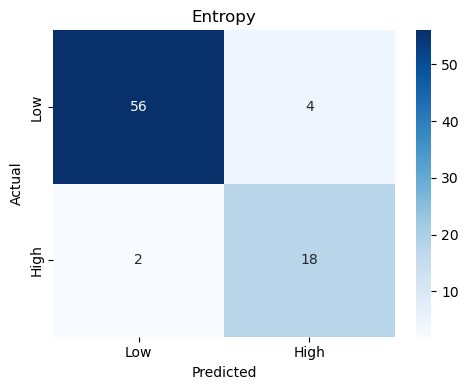

In [39]:
dt_entropy, entropy_train, entropy_test, y_train_pred_entropy, y_test_pred_entropy = train_tree("entropy")
cm_entropy = confusion_matrix(y_test, y_test_pred_entropy)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_entropy,annot=True,fmt="d",cmap="Blues",xticklabels=class_names,yticklabels=class_names)

plt.title("Entropy")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

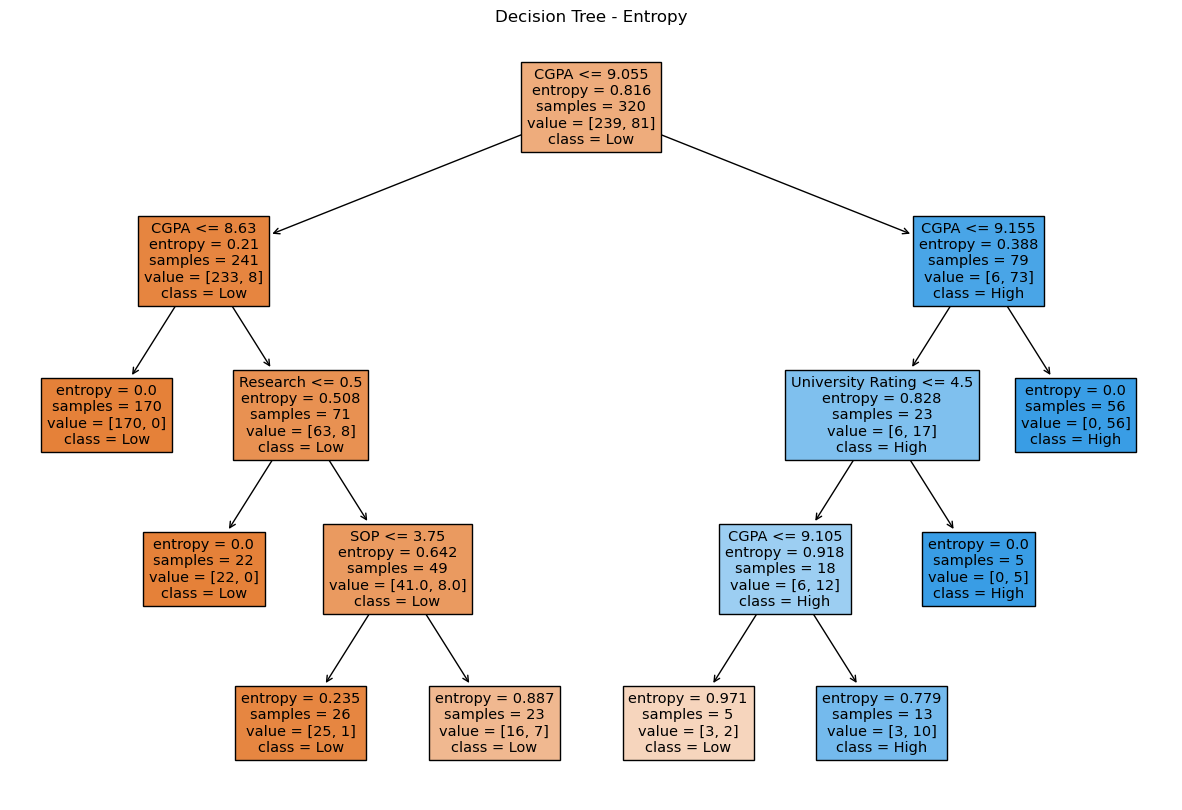

In [41]:
plt.figure(figsize=(15, 10))

plot_tree(dt_entropy,feature_names=X_train.columns,class_names=class_names,filled=True)

plt.title("Decision Tree - Entropy")
plt.show()

GINI Decision Tree

Training Metrics


,Accuracy,Precision,Recall,F1 Score
Training,0.96,0.9,0.95,0.92


Testing Metrics


,Accuracy,Precision,Recall,F1 Score
Testing,0.92,0.79,0.95,0.86


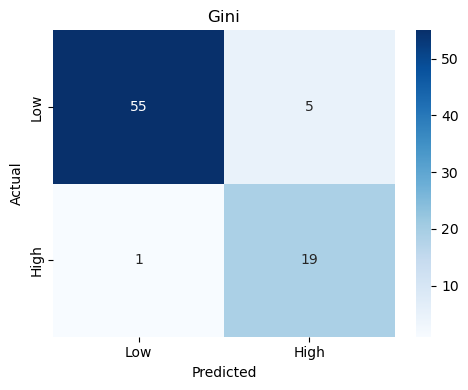

In [43]:
dt_gini, gini_train, gini_test, y_train_pred_gini, y_test_pred_gini = train_tree("gini")
cm_gini = confusion_matrix(y_test, y_test_pred_gini)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_gini,annot=True,fmt="d",cmap="Blues",xticklabels=class_names,yticklabels=class_names)

plt.title("Gini")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


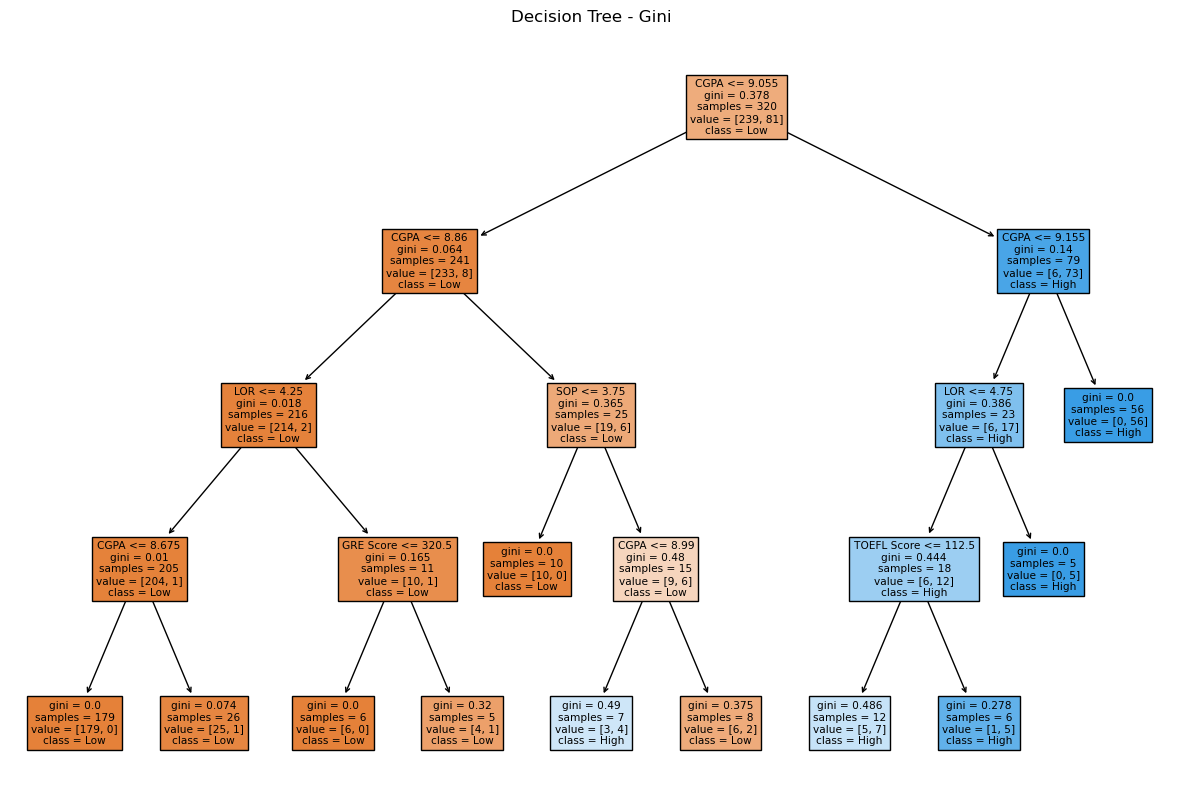

In [45]:
plt.figure(figsize=(15, 10))

plot_tree(dt_gini,feature_names=X_train.columns,class_names=class_names,filled=True)

plt.title("Decision Tree - Gini")
plt.show()

# Naive Bayes

In [48]:
nb = GaussianNB(priors=None,var_smoothing=1e-9)

nb.fit(X_train, y_train)

GaussianNB()

In [52]:
features = ["GRE Score","TOEFL Score","University Rating","SOP","LOR","CGPA","Research"]

X_high_low = X.copy()

for feature in features:
    X_high_low[feature] = np.where(X_high_low[feature] >= X_high_low[feature].median(),"High","Low")

X_high_low["Output"] = y.values

In [54]:
likelihood_tables = {}

for feature in features:

    table = pd.crosstab(
        X_high_low[feature],
        X_high_low["Output"],
        normalize="columns"
    )

    likelihood_tables[feature] = table

    print(f"\n{feature}")
    display(table.round(4))


output_probability = y.value_counts(normalize=True)

output_df = pd.DataFrame({
    "Output": output_probability.index,
    "Probability": output_probability.values,
    "Percentage (%)": output_probability.values * 100
})

output_df["Probability"] = output_df["Probability"].round(4)
output_df["Percentage (%)"] = output_df["Percentage (%)"].round(2)

display(output_df.style.hide(axis="index"))



GRE Score


Output,0,1
GRE Score,,
High,0.3512,0.9901
Low,0.6488,0.0099



TOEFL Score


Output,0,1
TOEFL Score,,
High,0.388,1.0
Low,0.612,0.0



University Rating


...


CGPA


Output,0,1
CGPA,,
High,0.3311,1.0
Low,0.6689,0.0



Research


Output,0,1
Research,,
High,0.4114,0.9505
Low,0.5886,0.0495


Output,Probability,Percentage (%)
0,0.747500,74.750000
1,0.252500,25.250000


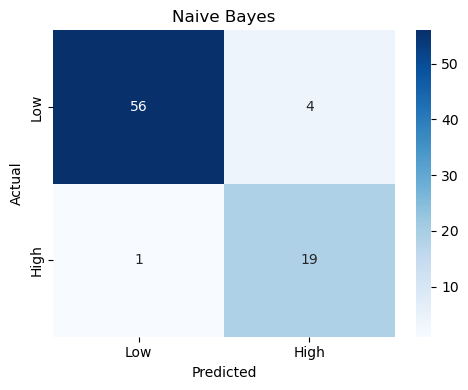

Categorical Naive Bayes

Training Metrics


,Accuracy,Precision,Recall,F1 Score
Training,0.92,0.78,0.93,0.85


Testing Metrics


,Accuracy,Precision,Recall,F1 Score
Testing,0.94,0.83,0.95,0.88


In [56]:
# Predictions
y_train_pred_nb = nb.predict(X_train)
y_test_pred_nb = nb.predict(X_test)

# Training metrics
nb_train_metrics = {
    "Accuracy": accuracy_score(y_train, y_train_pred_nb),
    "Precision": precision_score(y_train, y_train_pred_nb, zero_division=0),
    "Recall": recall_score(y_train, y_train_pred_nb, zero_division=0),
    "F1 Score": f1_score(y_train, y_train_pred_nb, zero_division=0)
}

# Testing metrics
nb_test_metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred_nb),
    "Precision": precision_score(y_test, y_test_pred_nb, zero_division=0),
    "Recall": recall_score(y_test, y_test_pred_nb, zero_division=0),
    "F1 Score": f1_score(y_test, y_test_pred_nb, zero_division=0)
}

cm_nb = confusion_matrix(y_test, y_test_pred_nb)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_nb,annot=True,fmt="d",cmap="Blues",xticklabels=class_names,yticklabels=class_names)

plt.title("Naive Bayes")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


print("Categorical Naive Bayes")

print("\nTraining Metrics")
display(pd.DataFrame([nb_train_metrics],index=["Training"]).round(2))

print("Testing Metrics")
display(pd.DataFrame([nb_test_metrics],index=["Testing"]).round(2))

# Compare Accuracy, Precision, Recall and F1

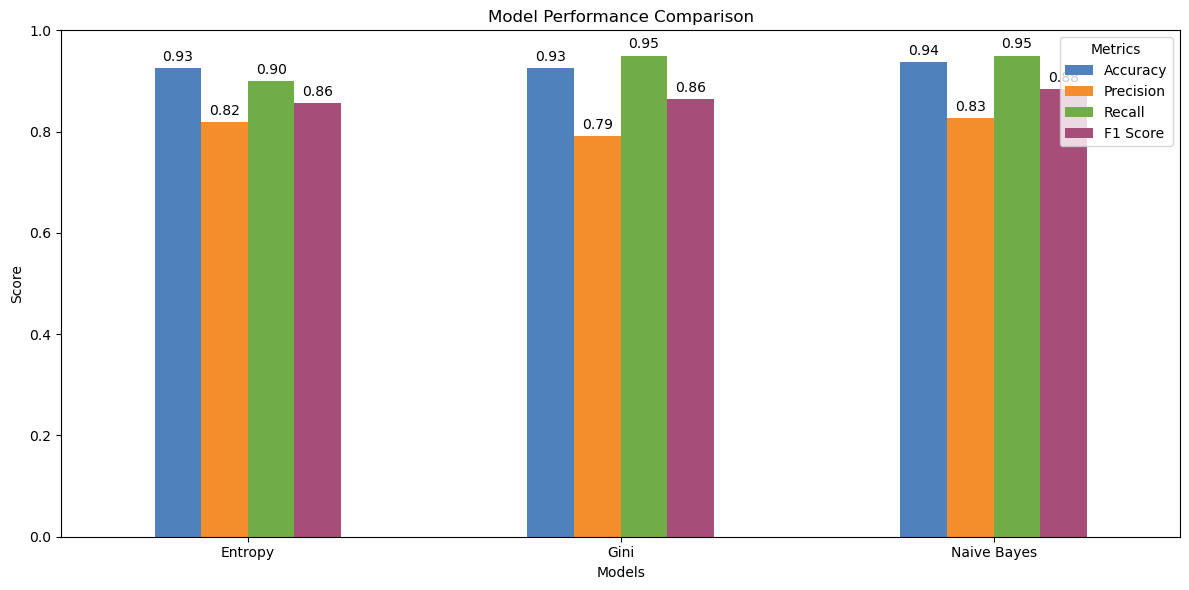

In [59]:
results = pd.DataFrame(
    [entropy_test, gini_test, nb_test_metrics],
    index=["Entropy", "Gini", "Naive Bayes"]
)

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

ax = results[metrics].plot(
    kind="bar",
    figsize=(12, 6),
    color=["#4F81BD", "#F28E2B", "#70AD47", "#A64D79"]
)

# Add values on top of bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.title("Model Performance Comparison")
plt.xlabel("Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()


In [61]:
def predict_student():

    print("Enter Student Details")
    print("-" * 40)
    print("Please enter values within the given ranges:\n")

    gre = float(input("Enter GRE Score (290-340): "))
    toefl = float(input("Enter TOEFL Score (92-120): "))
    university_rating = float(input("Enter University Rating (1-5): "))
    sop = float(input("Enter SOP (1-5): "))
    lor = float(input("Enter LOR (1-5): "))
    cgpa = float(input("Enter CGPA (6.8-9.92): "))
    research = int(input("Enter Research (0 = No, 1 = Yes): "))

    # Validate input ranges
    ranges = {
        "GRE Score": (gre, 290, 340),
        "TOEFL Score": (toefl, 92, 120),
        "University Rating": (university_rating, 1, 5),
        "SOP": (sop, 1, 5),
        "LOR": (lor, 1, 5),
        "CGPA": (cgpa, 6.8, 9.92),
        "Research": (research, 0, 1)
    }

    for name, (value, minimum, maximum) in ranges.items():
        if not minimum <= value <= maximum:
            print(
                f"Error: {name} must be between "
                f"{minimum} and {maximum}."
            )
            return

    if research not in [0, 1]:
        print("Error: Research must be 0 or 1.")
        return

    student = pd.DataFrame([{"GRE Score": gre,"TOEFL Score": toefl,"University Rating": university_rating,"SOP": sop,"LOR": lor,"CGPA": cgpa,"Research": research}])


    result = pd.DataFrame({
        "Model": ["Decision Tree (Entropy)","Decision Tree (Gini)","Naive Bayes"],
        "Prediction": [class_names[dt_entropy.predict(student)[0]],class_names[dt_gini.predict(student)[0]],class_names[nb.predict(student)[0]]]
    })

    return result


result = predict_student()

if result is not None:
    display(result)

Enter Student Details
----------------------------------------
Please enter values within the given ranges:



Enter GRE Score (290-340):  300
Enter TOEFL Score (92-120):  111
Enter University Rating (1-5):  5
Enter SOP (1-5):  5
Enter LOR (1-5):  5
Enter CGPA (6.8-9.92):  8.9
Enter Research (0 = No, 1 = Yes):  1


,Model,Prediction
0,Decision Tree (Entropy),Low
1,Decision Tree (Gini),High
2,Naive Bayes,Low
